<a href="https://colab.research.google.com/github/matiaspostay/IA-Clase3-Grupo-21/blob/main/notebooks/Grupo21_Clase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. MNIST Canvas

In [ ]:
import tensorflow as tf
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

model = keras.Sequential([
    keras.layers.Input(shape=(784,)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Accuracy en test:', test_acc)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8586 - loss: 0.4686 - val_accuracy: 0.9608 - val_loss: 0.1393
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9400 - loss: 0.2047 - val_accuracy: 0.9718 - val_loss: 0.1019
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9539 - loss: 0.1532 - val_accuracy: 0.9745 - val_loss: 0.0866
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9614 - loss: 0.1278 - val_accuracy: 0.9752 - val_loss: 0.0779
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9676 - loss: 0.1053 - val_accuracy: 0.9788 - val_loss: 0.0687
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9712 - loss: 0.0939 - val_accuracy: 0.9792 - val_loss: 0.0743
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9740 - loss: 0.0847 - val_accuracy: 0.9805 - val_loss: 0.0641
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9760 - loss: 0.0768 - val_accuracy: 

In [ ]:
from IPython.display import display, HTML
import base64, io
import numpy as np
from PIL import Image
from google.colab import output

# Callback en Python que procesa la imagen y hace la predicción
def predecir_imagen(base64_str):
    global model
    try:
        img_data = base64.b64decode(base64_str.split(',')[1])
        img = Image.open(io.BytesIO(img_data)).convert('L').resize((28, 28))
        # El lienzo tiene fondo blanco (255) y trazo negro (0). MNIST es al revés.
        entrada = (255.0 - np.array(img, dtype='float32')).reshape(1, 784) / 255.0

        probs = model.predict(entrada, verbose=0)[0]
        pred_clase = probs.argmax()
        porcentaje = probs.max() * 100

        # Devolver resultado formateado para mostrar en la interfaz HTML
        res_html = f"<b>Predicción: {pred_clase} ({porcentaje:.1f}%)</b><br>"
        res_html += "<br>".join([f"{i}: {p*100:.1f}%" for i, p in enumerate(probs)])
        return res_html
    except Exception as e:
        return f"Error al procesar: {str(e)}"

# Registrar la función de Python en Colab
output.register_callback('notebook.predecir_imagen', predecir_imagen)

display(HTML("""
<div style="display: flex; gap: 20px;">
  <div>
    <canvas id="lienzo" width="256" height="256" style="border:2px solid #333; cursor: crosshair;"></canvas><br>
    <button onclick="limpiarLienzo()" style="margin-top: 10px; padding: 5px 10px;">Limpiar</button>
    <button onclick="enviarPrediccion()" style="margin-top: 10px; padding: 5px 10px; background-color: #4CAF50; color: white; border: none;">Predecir</button>
  </div>
  <div id="resultado" style="font-family: monospace; padding: 10px; border: 1px solid #ccc; width: 200px; height: 256px; overflow-y: auto;">
    Dibuja un número y presiona 'Predecir'.
  </div>
</div>

<script>
const canvas = document.getElementById('lienzo');
const ctx = canvas.getContext('2d');
ctx.fillStyle = '#ffffff';
ctx.fillRect(0, 0, 256, 256);
ctx.lineWidth = 18;
ctx.lineCap = 'round';
ctx.strokeStyle = '#000000';

let dibujando = false;

canvas.onmousedown = e => { dibujando = true; ctx.beginPath(); ctx.moveTo(e.offsetX, e.offsetY); };
canvas.onmousemove = e => { if (dibujando) { ctx.lineTo(e.offsetX, e.offsetY); ctx.stroke(); } };
canvas.onmouseup = () => dibujando = false;
canvas.onmouseleave = () => dibujando = false;

function limpiarLienzo() {
  ctx.fillStyle = '#ffffff';
  ctx.fillRect(0, 0, 256, 256);
  document.getElementById('resultado').innerHTML = "Dibuja un número y presiona 'Predecir'.";
}

async function enviarPrediccion() {
  const dataUrl = canvas.toDataURL('image/png');
  document.getElementById('resultado').innerHTML = "Calculando...";

  // Llamar directamente al callback registrado en Python de manera segura
  const result = await google.colab.kernel.invokeFunction('notebook.predecir_imagen', [dataUrl], {});
  document.getElementById('resultado').innerHTML = result.data['text/plain'];
}
</script>
"""))

## 2. YOLO: detección de objetos

In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')   # se descarga automáticamente (~6 MB)
model.info()                 # cantidad de capas y parámetros reales

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 385.0ms
Speed: 18.2ms preprocess, 385.0ms inference, 31.2ms postprocess per image at shape (1, 3, 640, 480)
bus: 0.87
person: 0.87
person: 0.85
person: 0.83
person: 0.26
stop sign: 0.26


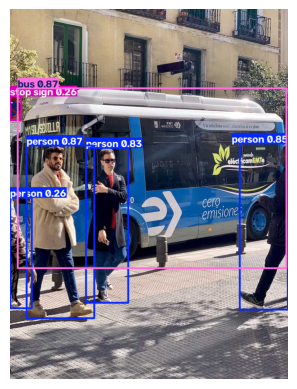

In [ ]:
results = model('https://ultralytics.com/images/bus.jpg')

for box in results[0].boxes:
    clase = model.names[int(box.cls)]
    confianza = float(box.conf)
    print(f'{clase}: {confianza:.2f}')

import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])  # BGR -> RGB
plt.axis('off')
plt.show()

Observación (MP):el modelo detectó 4 personas, 1 bus y 1 señal de pare, con una confianza de 0,87 para el bus y para dos de las personas. En la imagen se ve que el cartel de pare está cortado por el borde superior de la escena, y eso probablemente explica su confianza baja (0,26). También hay una cuarta persona que aparece recortada en el borde izquierdo, y su confianza es igual de baja (0,26). Por eso creemos que YOLO detecta bien los objetos completos y visibles, pero pierde seguridad cuando están tapados o fuera de cuadro.

## 3. Chat con LLM local (Ollama)

La app de chat corre en la PC de cada integrante, porque Colab no puede acceder a `localhost` de tu máquina.

**Pasos en tu PC:**
1. Instalar Ollama desde https://ollama.com
2. Descargar un modelo: `ollama pull llama3.2`
3. Verificar que la API responda: `curl http://localhost:11434/api/tags`
4. Hacer una pregunta desde la terminal con `ollama run llama3.2` o desde la app de chat, y sacar una captura.

In [20]:
import requests

try:
    respuesta = requests.post(
        'http://localhost:11434/api/generate',
        json={'model': 'llama3.2', 'prompt': '¿Qué es una red neuronal? Respondé en dos oraciones.', 'stream': False},
        timeout=60,
    )
    print(respuesta.json()['response'])
except requests.exceptions.ConnectionError:
    print('Ollama no está disponible en este entorno (Colab). Ejecutar esta celda en la PC local.')

Ollama no está disponible en este entorno (Colab). Ejecutar esta celda en la PC local.


**Captura del chat con Ollama (llama3.2 corriendo en la PC local):**

![Chat con Ollama](https://raw.githubusercontent.com/matiaspostay/IA-Clase3-Grupo-21/main/img/ollama_chat.png)

**Respuesta del modelo (llama3.2, en la PC local MP):**

"Una red neuronal (RN) es un sistema informático inspirado en el funcionamiento del cerebro humano, que consiste en una serie de capas de neuronas conectadas para procesar y aprender patrones en grandes cantidades de datos. Las RNs son capaces de aprender a partir de datos, hacer predicciones y tomar decisiones, lo que las hace muy útiles en aplicaciones como la inteligencia artificial, la automatización de procesos y el análisis de datos."

## Conclusiones

MP:

MNIST: con una red densa de 109.386 parámetros, el modelo alcanzó un 97,75 % de accuracy, un resultado muy bueno para una arquitectura simple. Esto demuestra que las redes neuronales pueden aprender eficazmente a reconocer patrones en imágenes.

Límites del modelo: si una imagen se rota 90°, es probable que el modelo falle o reduzca su precisión, ya que fue entrenado con imágenes en una orientación específica. Esto muestra que los modelos pueden tener dificultades ante situaciones diferentes a las vistas durante el entrenamiento.

YOLO: el modelo detectó correctamente los objetos más grandes y visibles, mientras que tuvo menor confianza en objetos pequeños o parcialmente ocultos. Nos pareció un comportamiento esperado, ya que estos casos presentan menos información visual para el reconocimiento.

Parámetros: verificamos que YOLOv8n posee 3.157.200 parámetros, una cantidad menor a la indicada en la diapositiva. Esto evidencia que puede lograr buenos resultados manteniendo una arquitectura eficiente.

Ollama y modelos locales: nos resultó interesante poder ejecutar un modelo de IA directamente en la computadora, sin conexión a internet. Aunque requiere instalación y algunos recursos de hardware, brinda mayor independencia y control sobre los datos.

Este TP me permitió conocer de forma práctica cómo funcionan distintos modelos de inteligencia artificial, comprendiendo tanto sus capacidades como sus limitaciones en aplicaciones reales.